# RK1 eval overnight: base vs S1 (plant + general), judge, checkpoint rule, test

Без переобучения: берёт адаптер с Drive `MyDrive/rk1_houseplant/s1_plant_qlora`.

1. Runtime → T4 GPU.
2. Secrets (ключ слева) → `OPENROUTER_API_KEY`, включить Notebook access.
3. Runtime → Run all. Вкладку не закрывать.

Всё пишется сразу в `MyDrive/rk1_houseplant/eval_s1/` построчно. Если runtime отвалился — просто Run all ещё раз: готовое пропускается.

Для быстрой проверки поставьте `SMOKE = True` (3 примера на набор, отдельная папка).

In [1]:
from google.colab import drive, userdata
import os

SMOKE = False

drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/rk1_houseplant'
ADAPTER = f'{DRIVE}/s1_plant_qlora'
OUT = f'{DRIVE}/eval_smoke' if SMOKE else f'{DRIVE}/eval_s1'
assert os.path.exists(f'{ADAPTER}/adapter_model.safetensors'), f'adapter not found in {ADAPTER}'
os.environ['OPENROUTER_API_KEY'] = userdata.get('OPENROUTER_API_KEY')
os.makedirs(OUT, exist_ok=True)
print('adapter:', sorted(os.listdir(ADAPTER)))
print('out:', OUT)

Mounted at /content/drive
adapter: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'added_tokens.json', 'chat_template.jinja', 'checkpoint-50', 'checkpoint-93', 'merges.txt', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.json']
out: /content/drive/MyDrive/rk1_houseplant/eval_s1


In [2]:
%cd /content
!git clone https://github.com/Schaft-s/LLM || (cd LLM && git pull)
%cd /content/LLM
!bash scripts/colab_install.sh
!git rev-parse HEAD > "{OUT}/git_commit.txt"
!mkdir -p "{OUT}/configs" && cp configs/*.yaml "{OUT}/configs/"
!nvidia-smi --query-gpu=name,memory.total --format=csv > "{OUT}/gpu.txt"

/content
Cloning into 'LLM'...
remote: Enumerating objects: 147, done.
remote: Counting objects: 100% (147/147), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 147 (delta 59), reused 123 (delta 35), pack-reused 0 (from 0)
Receiving objects: 100% (147/147), 729.13 KiB | 1.24 MiB/s, done.
Resolving deltas: 100% (59/59), done.
/content/LLM
Found existing installation: transformers 5.22.0
Uninstalling transformers-5.22.0:
  Successfully uninstalled transformers-5.22.0
Found existing installation: peft 0.21.2
Uninstalling peft-0.21.2:
  Successfully uninstalled peft-0.21.2
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which i

In [3]:
LIMIT = '--limit 3' if SMOKE else ''
!python scripts/run_eval_pipeline.py --out-dir "{OUT}" --adapter-root "{ADAPTER}" {LIMIT} 2>&1 | tee -a "{OUT}/run.log"

[22:07:30] candidates: ['s1_final', 's1_step50']
I0000 00:00:1793743659.719703    1801 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793743662.141638    1801 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Loading checkpoint shards: 100%|██████████| 2/2 [00:21<00:00, 10.74s/it]
[22:09:25] == baseline samples
[22:09:25]   baseline_samples__base.jsonl: 2 to generate (0 done)
[22:10:00]     2/2 (35s/batch)
[22:10:00]   baseline_samples__s1_final.jsonl: 2 to generate (0 done)
[22:10:13]     2/2 (13s/batch)
[22:10:13] == dev / base
[22:10:13]   general_dev__base.jsonl: 80 to generate (0 done)
[22:10:14]     8/80 (1s/batch)
[22:10:15]     16/80 (1s/batch)
[22:10:16]     24/80 (1s/batch)
[22:10:17]     32/80 (1s/batch)
[22:10:1

# RK1 eval summary

Selected: **base**


## dev

| variant | general acc | format pass | judge mean (0-8) | critical err | c→w | w→c |
|---|---:|---:|---:|---:|---:|---:|
| base | 0.825 | 0.92 | 6.54 | 0.03 | - | - |
| s1_final | 0.863 | 0.18 | 3.15 | 0.28 | 3 | 6 |
| s1_step50 | 0.863 | 0.23 | 2.97 | 0.28 | 3 | 6 |

Per-category general accuracy:

| variant | arc_easy | arith | extract | json_schema | logic | stable_facts | units |
|---|---:|---:|---:|---:|---:|---:|---:|
| base | 0.95 | 0.90 | 1.00 | 1.00 | 0.60 | 0.80 | 0.40 |
| s1_final | 1.00 | 0.70 | 1.00 | 1.00 | 0.60 | 1.00 | 0.60 |
| s1_step50 | 1.00 | 0.70 | 1.00 | 1.00 | 0.60 | 1.00 | 0.60 |

## test

| variant | general acc | format pass | judge mean (0-8) | critical err | c→w | w→c |
|---|---:|---:|---:|---:|---:|---:|
| base | 0.819 | 0.97 | 6.64 | 0.00 | - | - |
| s1_final | 0.863 | 0.13 | 3.67 | 0.13 | 4 | 11 |

Per-category general accuracy:

| variant | arc_easy | arith | extract | json_schema | logic | stable_facts | units |
|---|---:|---:|---:|---:|---:|---:|---:|
| base | 0.90 | 1.00 | 1.00 | 1.00 | 0.50 | 0.85 | 0.40 |
| s1_final | 0.95 | 0.95 | 1.00 | 1.00 | 0.55 | 0.85 | 0.65 |

- rule check `s1_final`: pass=False {"general_drop_pp": -3.750000000000009, "general_ok": true, "plant_ok": false, "plant_basis": "judge_mean_total"}

- rule check `s1_step50`: pass=False {"general_drop_pp": -3.750000000000009, "general_ok": true, "plant_ok": false, "plant_basis": "judge_mean_total"}


/content/drive/MyDrive/rk1_houseplant/eval_s1/plots/general_dev_per_category.png


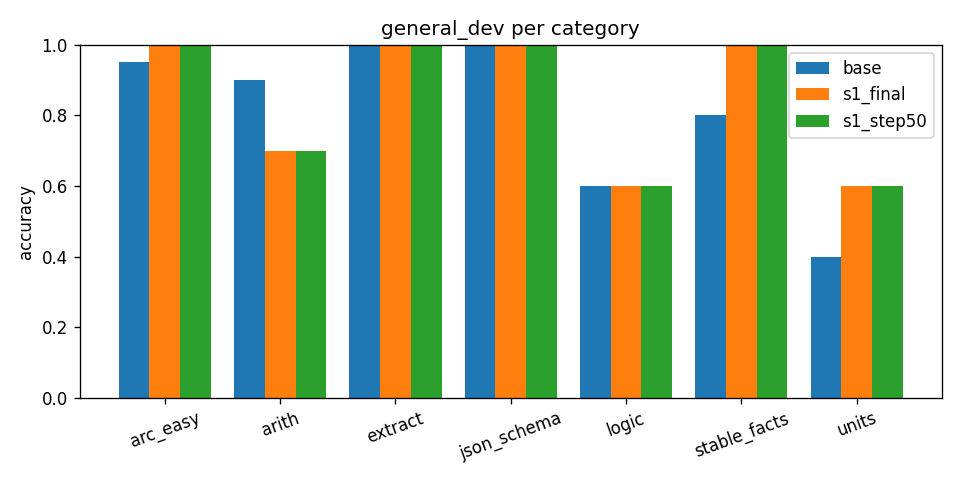

/content/drive/MyDrive/rk1_houseplant/eval_s1/plots/general_test_per_category.png


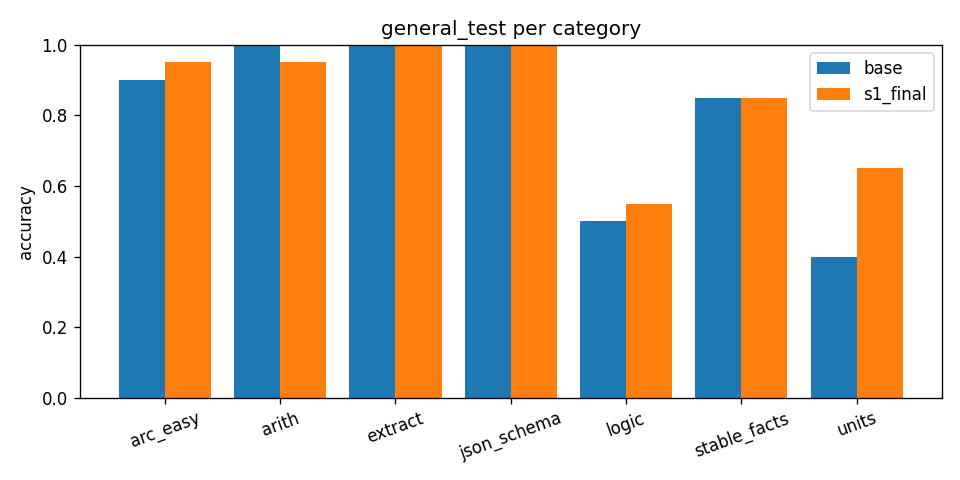

/content/drive/MyDrive/rk1_houseplant/eval_s1/plots/judge_plant_dev.png


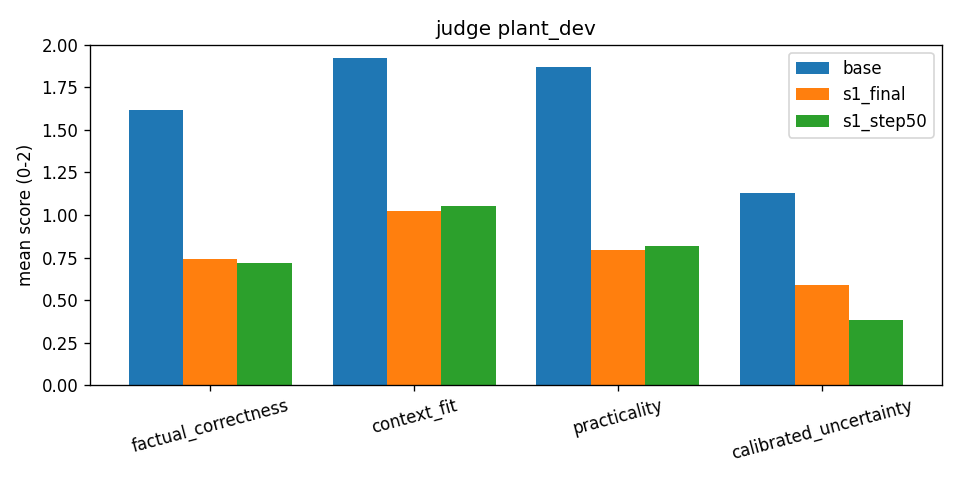

/content/drive/MyDrive/rk1_houseplant/eval_s1/plots/judge_plant_test.png


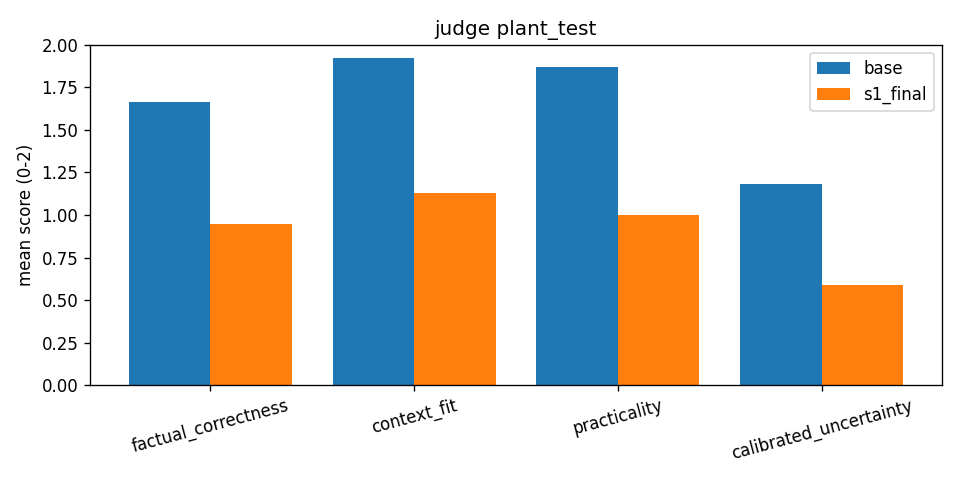

/content/drive/MyDrive/rk1_houseplant/eval_s1/plots/train_loss.png


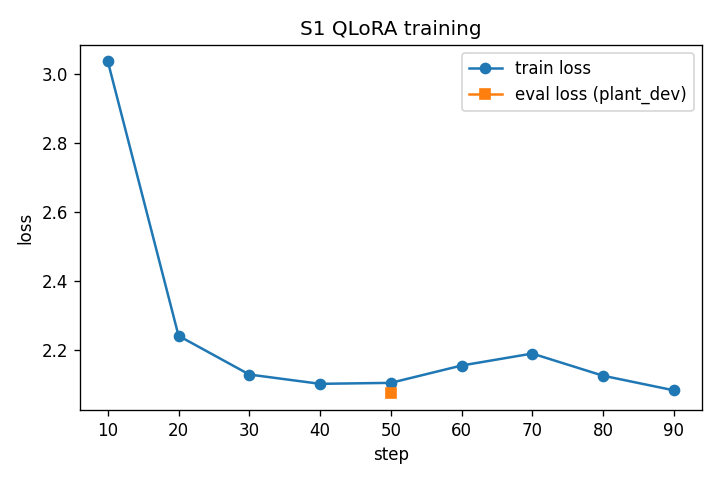

Drive flushed


In [4]:
import glob
from IPython.display import Image, Markdown, display

display(Markdown(open(f'{OUT}/summary.md').read()))
for p in sorted(glob.glob(f'{OUT}/plots/*.png')):
    print(p)
    display(Image(p))
drive.flush_and_unmount()
print('Drive flushed')